[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Naviden/Introduction-to-XAI/blob/main/Tools/Starter_examples/First_XAI_Comparison.ipynb)

[Colab setup: dependencies and repository files](https://github.com/Naviden/Introduction-to-XAI/blob/main/docs/REPRODUCIBILITY.md#google-colab)

# Your first XAI comparison: one model, one case

**Question:** which inputs matter to a classifier overall, and which contribute to one prediction?

Use a bundled dataset and a small random forest to compare **permutation importance, SHAP and LIME**. The local methods explain the **same case, model and malignant-class probability**. Their explanations answer different questions, so agreement is not a correctness test.

- **Audience:** beginners who know train/test splits and classification probabilities.
- **Setup:** from the repository root, install `requirements-tabular.txt`, then open this notebook. No Java, pretrained weights, GPU, or network downloads are needed after installing packages.
- **Budget:** designed for a short CPU run; measured execution time depends on hardware and cold imports.
- **Outcome:** read a global ranking, verify an additive local explanation, and inspect a local approximation's fit.
- **Scope:** an educational model of a historical medical dataset; the results are not clinical recommendations.

In [1]:
import time
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from IPython.display import display
from lime.lime_tabular import LimeTabularExplainer
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import train_test_split

SEED = 42
started = time.perf_counter()
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
display(pd.Series({name: metadata.version(name) for name in ['numpy', 'pandas', 'scikit-learn', 'shap', 'lime']}, name='version'))

/Users/navid/Documents/Codex/2026-10-28/makew/work/Introduction-to-XAI/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


numpy             2.4.6
pandas            2.3.3
scikit-learn      1.9.1
shap             0.51.0
lime            0.2.0.1
Name: version, dtype: object

## Fit once and keep the test set separate

Scikit-learn bundles the Wisconsin Diagnostic Breast Cancer dataset: 569 cases and 30 numeric measurements. We explicitly recode **malignant = 1** and **benign = 0**. A stratified split preserves their proportions. Model settings are fixed before inspecting test performance; this is a demonstration, not hyperparameter selection.

In [2]:
dataset = load_breast_cancer(as_frame=True)
X = dataset.data.copy()
y = (dataset.target == 0).astype(int).rename('malignant')
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
assert set(X_train.index).isdisjoint(X_test.index)
model = RandomForestClassifier(n_estimators=100, max_depth=5, min_samples_leaf=2, n_jobs=2, random_state=SEED)
model.fit(X_train, y_train)
class_index = int(np.flatnonzero(model.classes_ == 1)[0])
probabilities = model.predict_proba(X_test)[:, class_index]
display(pd.Series({'training_cases': len(X_train), 'test_cases': len(X_test),
                   'test_accuracy': accuracy_score(y_test, model.predict(X_test)),
                   'test_roc_auc': roc_auc_score(y_test, probabilities)}, name='model checks'))

training_cases    426.000000
test_cases        143.000000
test_accuracy       0.965035
test_roc_auc        0.995178
Name: model checks, dtype: float64

## Global question: what happens when a feature is shuffled?

Permutation importance measures the held-out **ROC AUC loss** after shuffling each feature. The bars average five shuffles; error bars show their standard deviation, **not a population confidence interval**. A near-zero score can mean redundancy with correlated measurements, not that a feature is irrelevant. Shuffling can also create implausible feature combinations.

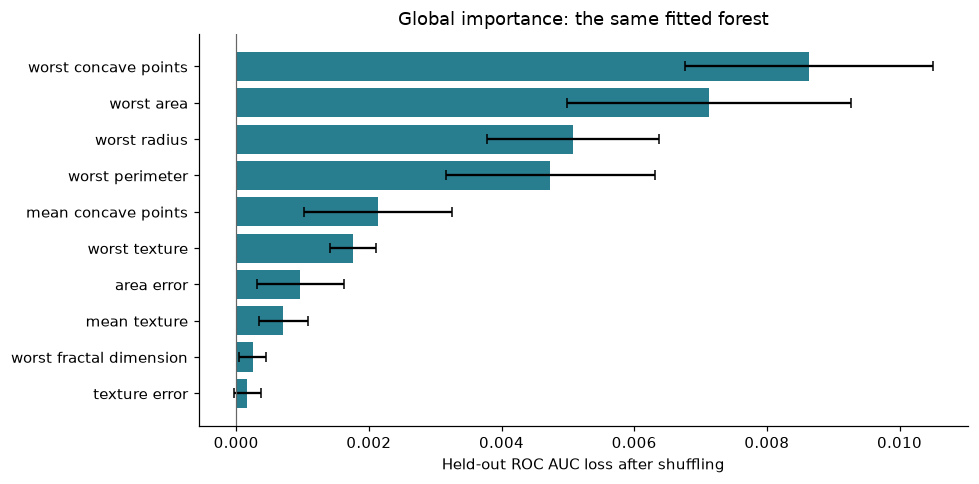

In [3]:
permutation = permutation_importance(model, X_test, y_test, scoring='roc_auc', n_repeats=5, random_state=SEED, n_jobs=1)
importance = pd.DataFrame({'feature': X.columns, 'mean_auc_loss': permutation.importances_mean,
                           'shuffle_sd': permutation.importances_std}).set_index('feature')
shown = importance.nlargest(10, 'mean_auc_loss').sort_values('mean_auc_loss')
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(shown.index, shown.mean_auc_loss, xerr=shown.shuffle_sd, color='#287D8E', capsize=3)
ax.axvline(0, color='0.4', linewidth=0.8)
ax.set(xlabel='Held-out ROC AUC loss after shuffling', title='Global importance: the same fitted forest')
fig.tight_layout()
plt.show()

## Fix one case and one output

For a readable example, select a correctly classified malignant test case whose probability is closest to 0.70. This deliberately chosen illustration is not representative of every test case; it does not change the model or the reported test metrics. Both local methods use this exact input and class.

In [4]:
candidates = np.flatnonzero((y_test.to_numpy() == 1) & (probabilities >= 0.5))
if not len(candidates):
    raise RuntimeError('No correctly classified malignant test case; inspect model performance before explaining it.')
query_position = int(candidates[np.argmin(np.abs(probabilities[candidates] - 0.70))])
query = X_test.iloc[[query_position]]
query_probability = float(model.predict_proba(query)[0, class_index])
print(f'Original dataset row: {query.index[0]}; true label: malignant; P(malignant): {query_probability:.4f}')

Original dataset row: 190; true label: malignant; P(malignant): 0.7045


## SHAP: an additive explanation of this prediction

Tree SHAP allocates the difference from a reference value among the features. Here we explicitly use the **tree-path-dependent** reference, derived from the training sample counts stored in the trees. This choice matters when features are correlated. For this scikit-learn random forest, the explained output is a probability; other model types may use log-odds instead.

We verify the equation `reference + sum(contributions) = model probability`. Passing this check verifies an additive reconstruction, not causal importance or a uniquely correct attribution.

SHAP reference: 0.3746; reconstructed P(malignant): 0.7045


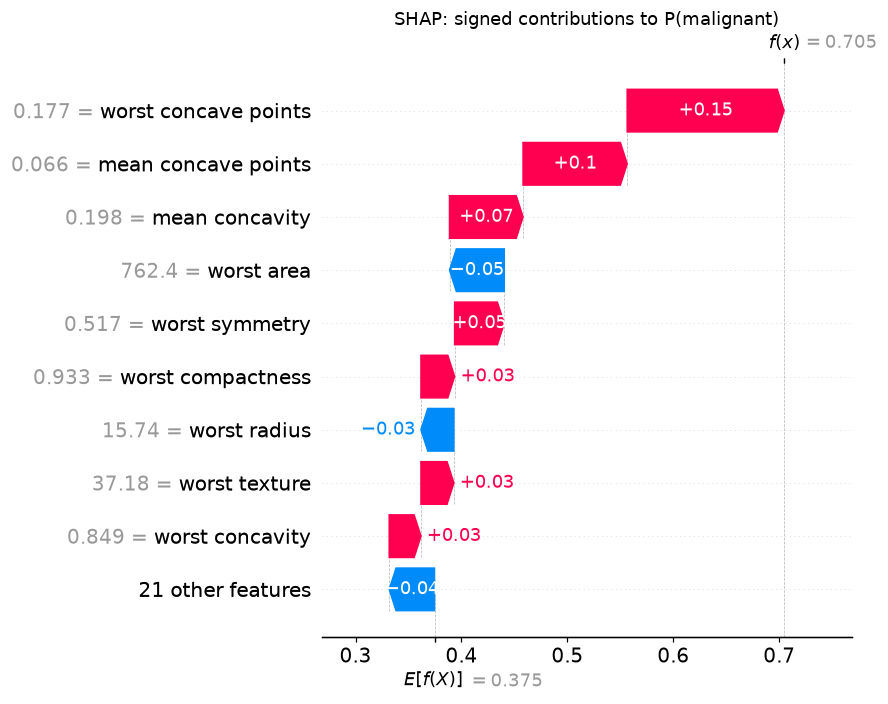

In [5]:
tree_explainer = shap.TreeExplainer(model, feature_perturbation='tree_path_dependent')
all_classes = tree_explainer(query)
local_shap = all_classes[0, :, class_index]
reconstructed_probability = float(local_shap.base_values + local_shap.values.sum())
np.testing.assert_allclose(reconstructed_probability, query_probability, atol=1e-6)
print(f'SHAP reference: {float(local_shap.base_values):.4f}; reconstructed P(malignant): {reconstructed_probability:.4f}')
shap.plots.waterfall(local_shap, max_display=10, show=False)
plt.title('SHAP: signed contributions to P(malignant)')
plt.tight_layout()
plt.show()

## LIME: how well does a simple local story fit?

LIME samples perturbed inputs and fits a small weighted linear model near the case. It reports **discretized conditions**, not the same quantities as SHAP values. The weighted local R² evaluates fit on LIME's artificial neighborhood; the probability gap below evaluates the approximation at the case. Neither is a held-out guarantee across real patients. In correlated data, the sampled neighborhood can be unrealistic.

A small probability gap at the case does not compensate for a low neighborhood R². If the local fit is poor, treat the displayed conditions as an inadequate summary and inspect other neighborhoods or methods.

Weighted local R²: 0.205
LIME approximation: 0.6735; forest: 0.7045; absolute gap: 0.0310


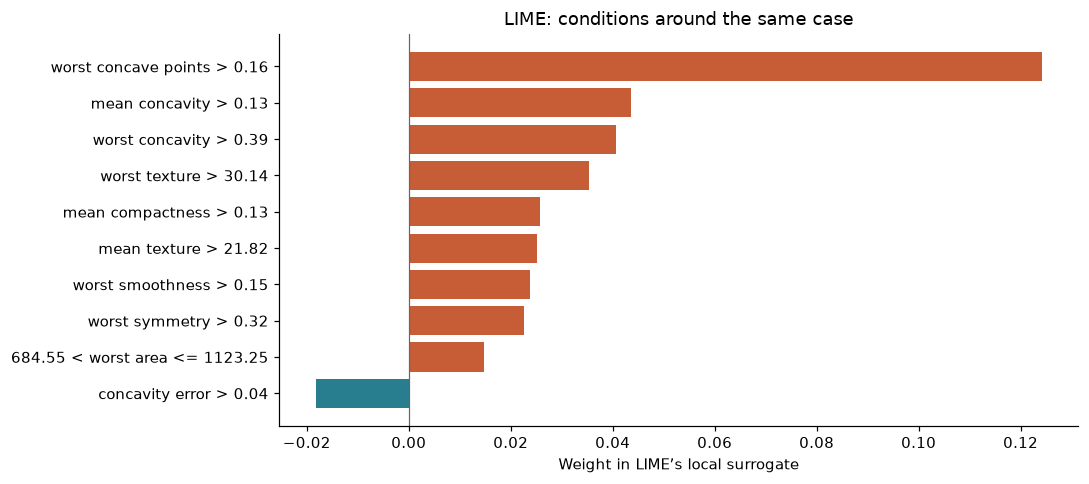

In [6]:
def predict_probabilities(rows):
    return model.predict_proba(pd.DataFrame(rows, columns=X.columns))

lime_explainer = LimeTabularExplainer(X_train.to_numpy(), feature_names=X.columns.tolist(),
                                    class_names=['benign', 'malignant'], mode='classification',
                                    discretize_continuous=True, random_state=SEED)
local_lime = lime_explainer.explain_instance(query.iloc[0].to_numpy(), predict_probabilities,
                                          labels=(class_index,), num_features=10, num_samples=3000)
lime_probability = float(local_lime.local_pred[0])
print(f'Weighted local R²: {local_lime.score:.3f}')
print(f'LIME approximation: {lime_probability:.4f}; forest: {query_probability:.4f}; absolute gap: {abs(lime_probability-query_probability):.4f}')
weights = pd.Series(dict(local_lime.as_list(label=class_index))).sort_values()
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(weights.index, weights.values, color=['#287D8E' if w < 0 else '#C65D36' for w in weights.values])
ax.axvline(0, color='0.4', linewidth=0.8)
ax.set(xlabel='Weight in LIME’s local surrogate', title='LIME: conditions around the same case')
fig.tight_layout()
plt.show()

## Use each result for the question it answers

| Output | What it describes | Check before using it |
|---|---|---|
| Permutation ranking | Change in a selected predictive metric after shuffling | Model performance, feature dependence, shuffle variation |
| SHAP waterfall | Additive allocation under a specified reference | Correct class and output units, additivity, reference choice |
| LIME conditions | A local surrogate on a sampled neighborhood | Local fit, approximation gap, realistic perturbations, repeated-seed stability |

Do not average these scores into a single importance value or treat agreement as proof of correctness. A model can rely on a spurious pattern while its explanation faithfully describes that pattern. This dataset does not establish that changing a measurement changes a diagnosis.

In [7]:
diagnostics = pd.DataFrame([
    {'check': 'SHAP reconstruction absolute error', 'value': abs(reconstructed_probability-query_probability), 'meaning': 'probability units; close to zero checks additivity'},
    {'check': 'LIME weighted local R²', 'value': local_lime.score, 'meaning': 'fit on sampled neighborhood; higher is better for that neighborhood'},
    {'check': 'LIME case approximation absolute gap', 'value': abs(lime_probability-query_probability), 'meaning': 'probability units; inspect alongside local R²'},
])
display(diagnostics)
print(f'Notebook calculation time after imports: {time.perf_counter()-started:.1f} seconds')

,check,value,meaning
0,SHAP reconstruction absolute error,1.110223e-16,probability units; close to zero checks additi...
1,LIME weighted local R²,2.049440e-01,fit on sampled neighborhood; higher is better ...
2,LIME case approximation absolute gap,3.100025e-02,probability units; inspect alongside local R²


Notebook calculation time after imports: 2.7 seconds


## Next experiments

1. Repeat LIME with several seeds. Does its selected feature set change while the forest probability remains fixed?
2. Explain a misclassified case and compare it with this deliberately chosen correct case.
3. Change SHAP's reference to a documented training background with interventional perturbations. Explain why the allocation changes.
4. Continue with [intrinsically interpretable models](../../../../Tools/InterpretableModels_examples/Interpretable_Models_Comparison.ipynb), or the [complete shared-case comparison](../../../../Tools/MethodComparison_examples/Shared_Tabular_Case_Comparison.ipynb), which needs additional dependencies.

## Sources and provenance

- Dataset: [scikit-learn breast-cancer loader and original dataset references](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html).
- Permutation definition and limitations: [scikit-learn inspection guide](https://scikit-learn.org/stable/modules/permutation_importance.html).
- SHAP: [Lundberg and Lee, 2017](https://arxiv.org/abs/1705.07874); [TreeExplainer reference choices](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html).
- LIME: [Ribeiro, Singh and Guestrin, 2016](https://arxiv.org/abs/1602.04938).